# N-Gram Sprachmodelle

## TODO:

- Beschreibung N-Gram
- `load_data()` Funktion: Lädt TinyShakespeare
- `build_vocabulary()` Funktion: Data -> Vokabular (Wort, Zeichenebene)
- `build_n_gram_matrix()` Funktion: Erstellt N-Gram Modell
- `NGram`: class with `generate()`, `show()`, ... Methoden


In [1]:
from utils import (
    load_data,
    tokenize,
    build_vocabulary,
    to_chunks,
    make_toy_dataset
)
from ngram import NGram

In [2]:
LEVEL = "char"
DATASET = "assets/toy.txt"
SEPARATOR = None #"\n\n"
N = 3
VOCAB = "abcdef "
_ = make_toy_dataset(
    path="assets/toy.txt",
    vocabulary=VOCAB,
    length=20_000,
    alpha=0.3
)

# TODO: make this only interaction point with data? although i think the individual steps are instructive
def prepare_data(
        dataset: str,
        level: str,
        separator: str,
):
    # Lädt den Datensatz
    data = load_data(source=dataset)

    # Erstellt "Chunks", im Fall von Shakespeare: 1 Chunk = 1 Sprechakt
    # und wandelt die Chunks in Tokens um
    chunks = [tokenize(c, level) for c in to_chunks(text=data, separator=separator) if c.strip()]

    # Erstellt das Vokabular aus den Chunks
    vocabulary = build_vocabulary([t for doc in chunks for t in doc])
    return chunks, vocabulary

prepared_data, vocab = prepare_data(DATASET, LEVEL, SEPARATOR)
ngram = NGram(n=N, level=LEVEL).fit(prepared_data, vocab)


### N-Gram Visualisierung

* Das ngram ist im prinzip nur eine assoziationsmatrix kontext -> folgetoken
* wir können das visualisieren: reihen sind der kontext, spalten das nächste token (zelle deutet übergangswahrscheinlichkeit an)
* um das nächste token zu produzieren, samplen wir per Reihe (zB wenn "ff" gegeben, dann ist nächstwahrscheinlichstes token wieder ein "f" (p=0.6459)

In [11]:
ngram.show_association_matrix()

↓→,␣,a,b,c,d,e,f
fc,,,,,,,
cf,,,,,,,
bb,,,,,,,
␣c,,,,,,,
c␣,,,,,,,
cc,,,,,,,
ba,,,,,,,
cb,,,,,,,
␣f,,,,,,,
eb,,,,,,,


* größe der matrix wächst exponentiell: vocab^n einträge (vocab^(n-1) reihen * vocab spalten) -> unpraktisch (vocab size 5):

| N | Reihen | Einträge |
|---|--------|----------|
| 2 | 5      |  25      |
| 3 | 25      |  125      |
| 4 | 125      |  625      |
| 5 | 625      |  3125      |
| 6 | 3125      |  15.625      |
| 7 | 15625      |  78.125      |
| 8 | 78125      |  390.625      |
| 9 | 390625      |  1.953.125      |

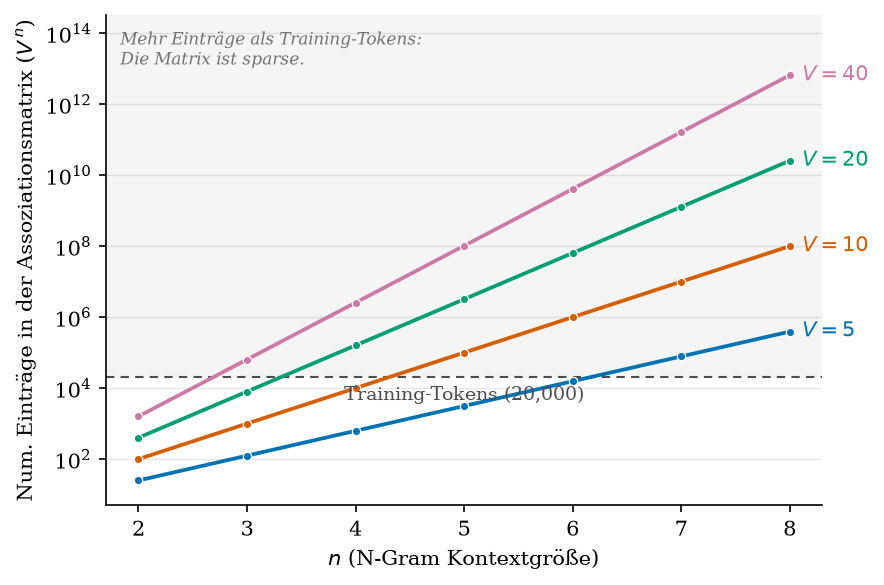

In [10]:
from viz import plot_ngram_matrix_size

vocab_sizes = (5, 10, 20, 40)
n_grams = (2, 3, 4, 5, 6, 7, 8)
training_size = sum(len(doc) for doc in prepared_data)

_ = plot_ngram_matrix_size(
    vocab_sizes=vocab_sizes,
    n_grams=n_grams,
    training_size=training_size,
)

## Generieren neuer Token

In [5]:
LENGTH = 500
STREAM = True
DELAY = 0.05
PROMPT = ""

_ = ngram.generate(LENGTH, PROMPT, stream=STREAM)

dddddebc cbebcfcfcfc fc ccfcfcfcfcfcbbafcfcfcba cc cfcf cfcffcfcfcfcfc fcfcfcffcbbbbbbbbbbbbbbbc cfc fccfcfc fcfcf cfcfccfcffcbbbbafcfcfcfcfcfcf cf c cfcfcfcfcfcfc cfcfcfcfcfcfcfcfc ccfc cfcfcfcfcfcfcffc fc cfc cfc cf fcfc c ccccfcfcf ddbbbbbba debbbbbbafccfcfc cfcfc cfcfcfcfc cfcfccfcfcfcfcc cfc fcfcfc ccfcfccfcfcfcffcfcfcfc deba cfccfc fcfccfcfcfcffc cbbbbcfc dddddddebbbbbbbbbbbbbbbafcfcfccfcf cfcfccc cfcfcfcfc cfcfc fcfc cfcfc cfcfcfcc cfcccfcbbbbafcfcfc cfccffc fcfcfcfcfcfcfcfcfcfc cfcfcfc c